# AMD-SD: first look at the data

Goal: understand what is in the dataset before building anything.

1. How the files are laid out (scan and mask in one PNG)
2. Turning the colour mask into class labels
3. Checking the train/validation split for leakage
4. How many lesions of each type, and how big they are
5. A data-quality check (colour bleed at the panel seam)
6. The demographics file
7. Picking the scans with the smallest IRF lesions, for the denoising experiment

**Key terms.** A *pixel* is one square of the image grid (each panel is 570 × 380 pixels).
A *lesion* (informally a "pocket") is a group of touching pixels of the same class in the mask.
Its *size* is the number of pixels in it.

Requirements: `numpy pillow scipy matplotlib pandas openpyxl`
(e.g. `uv pip install numpy pillow scipy matplotlib pandas openpyxl`).

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage
import matplotlib.pyplot as plt

# The notebook lives in AMD-SD/_analysis, so the dataset root is one level up.
ROOT = Path.cwd().parent if Path.cwd().name == "_analysis" else Path.cwd()
IMG_DIR = ROOT / "images"
print("Dataset root:", ROOT)
print("Eye folders:", len(list(IMG_DIR.iterdir())))

Dataset root: /Users/atharvax/dev/Retinal_OCT/AMD-SD
Eye folders: 157


## 1. File layout

Each PNG is **1140 × 380**: the OCT B-scan on the left (570 px wide) and the expert mask on the right.
Folder name = eye ID, file name = `<eye>_<scan>.png`. All scans come from a Zeiss Cirrus HD-5000.

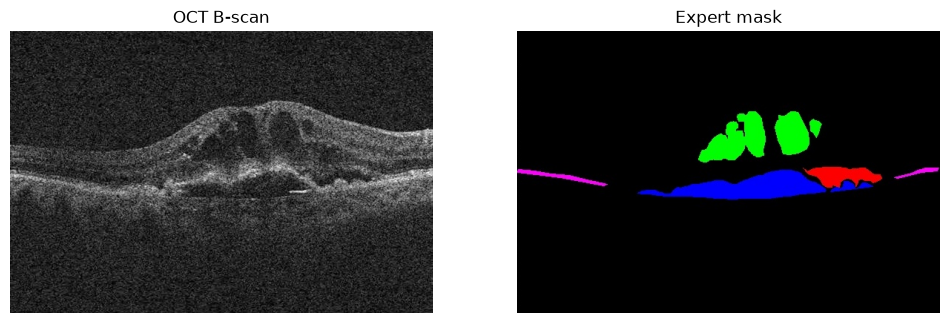

In [11]:
W = 570  # width of each panel

def load(path):
    a = np.asarray(Image.open(path).convert("RGB"))
    assert a.shape == (380, 2 * W, 3), a.shape
    oct_gray = a[:, :W].mean(-1).astype(np.uint8)  # scan as greyscale
    mask_rgb = a[:, W:]
    return oct_gray, mask_rgb

example = IMG_DIR / "50" / "50_10.png"
oct_img, mask_rgb = load(example)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(oct_img, cmap="gray"); ax[0].set_title("OCT B-scan")
ax[1].imshow(mask_rgb); ax[1].set_title("Expert mask")
for a in ax: a.axis("off")
plt.show()

## 2. Decoding the colour mask

Colours from the dataset paper (Hu et al., *Scientific Data* 2024):
SRF red, IRF green, PED blue, SHRM yellow, ellipsoid zone (IS/OS) pink, background black.

The PNGs have slightly blended colours at edges, so each mask pixel is assigned to the **nearest**
reference colour, and left unassigned (−1) if it is far from all of them.

In [12]:
PALETTE = {
    "background": (0, 0, 0),
    "SRF":  (255, 0, 0),
    "IRF":  (0, 255, 0),
    "PED":  (0, 0, 255),
    "SHRM": (255, 255, 0),
    "ISOS": (255, 0, 255),   # ellipsoid zone: a layer, not a lesion
}
NAMES = list(PALETTE)
REF = np.array([PALETTE[k] for k in NAMES], dtype=np.int32)
LESIONS = ["SRF", "IRF", "PED", "SHRM"]
MAX_DIST = 120

def decode(mask_rgb):
    d = ((mask_rgb[..., None, :].astype(np.int32) - REF) ** 2).sum(-1)
    lab = d.argmin(-1)
    lab[np.sqrt(d.min(-1)) > MAX_DIST] = -1
    return lab   # 0 = background, 1..5 = classes in NAMES order, -1 = unassigned

lab = decode(mask_rgb)
for i, n in enumerate(NAMES):
    print(f"{n:10s} {int((lab == i).sum()):6d} px")
print(f"unassigned {int((lab == -1).sum()):6d} px")

background 202542 px
SRF          1719 px
IRF          5755 px
PED          5493 px
SHRM            0 px
ISOS          813 px
unassigned    278 px


## 3. Train / validation split

The dataset ships `training.txt` and `validation.txt` (80:20).
The important check: **no eye or patient appears in both**, otherwise the test set leaks.

In [13]:
def read_split(name):
    return {Path(l.strip()).name for l in open(ROOT / name) if l.strip()}

train_names, val_names = read_split("training.txt"), read_split("validation.txt")
split_of = {**{n: "train" for n in train_names}, **{n: "val" for n in val_names}}
eye_of = lambda n: n.split("_")[0]

train_eyes = {eye_of(n) for n in train_names}
val_eyes = {eye_of(n) for n in val_names}
print("train scans:", len(train_names), " val scans:", len(val_names))
print("eyes in both splits:", len(train_eyes & val_eyes))

train scans: 2346  val scans: 703
eyes in both splits: 0


## 4. Lesions per class and their sizes

For every scan, each class's pixels are grouped into **connected components** (touching pixels,
including diagonals). Each component is one lesion. Components under 3 px are treated as
compression noise. This loop reads all 3,049 images and takes about 1–2 minutes.

In [14]:
files = sorted(IMG_DIR.glob("*/*.png"))
img_rows, les_rows = [], []

for f in files:
    _, m = load(f)
    lab = decode(m)
    row = {"image": f.name, "eye": f.parent.name, "split": split_of.get(f.name, "missing")}
    for ci, cname in enumerate(NAMES[1:], start=1):
        binary = lab == ci
        row[f"{cname}_px"] = int(binary.sum())
        if cname not in LESIONS:
            continue
        comp, n = ndimage.label(binary, structure=np.ones((3, 3)))
        kept = 0
        if n:
            areas = ndimage.sum(binary, comp, range(1, n + 1))
            for area, box in zip(areas, ndimage.find_objects(comp)):
                if area < 3:
                    continue
                kept += 1
                les_rows.append({"image": f.name, "eye": f.parent.name, "split": row["split"],
                                 "class": cname, "area_px": int(area),
                                 "height_px": box[0].stop - box[0].start,
                                 "width_px": box[1].stop - box[1].start})
        row[f"{cname}_n"] = kept
    img_rows.append(row)

per_image = pd.DataFrame(img_rows)
per_lesion = pd.DataFrame(les_rows)
per_image.to_csv("per_image.csv", index=False)
per_lesion.to_csv("per_lesion.csv", index=False)
print(len(per_image), "scans,", len(per_lesion), "lesions")

3049 scans, 10000 lesions


In [15]:
summary = []
for c in LESIONS:
    a = per_lesion.loc[per_lesion["class"] == c, "area_px"]
    has = (per_image[f"{c}_px"] > 0).sum()
    summary.append({"class": c, "scans with it": has, "% scans": round(100 * has / len(per_image), 1),
                    "lesions": len(a), "median px": int(a.median()),
                    "< 50 px": int((a < 50).sum()), "< 200 px": int((a < 200).sum())})
summary = pd.DataFrame(summary).set_index("class")
no_lesion = (per_image[[f"{c}_px" for c in LESIONS]].sum(1) == 0).sum()
print("scans with no lesion:", no_lesion)
summary

scans with no lesion: 171


/var/folders/dt/_jymhl_n7k7by5rpm7pmf4s80000gn/T/ipykernel_17911/3979725979.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  no_lesion = (per_image[[f"{c}_px" for c in LESIONS]].sum(1) == 0).sum()


,scans with it,% scans,lesions,median px,< 50 px,< 200 px
class,,,,,,
SRF,1787,58.6,2668,945,91,447
IRF,725,23.8,2322,165,441,1291
PED,2084,68.4,3066,739,133,712
SHRM,1625,53.3,1944,2159,36,120


IRF is the small-lesion class: most IRF lesions are under 200 px, while SRF, PED and SHRM are
mostly large. That gives hypothesis H2 a target (IRF) and a comparison group (the large classes).

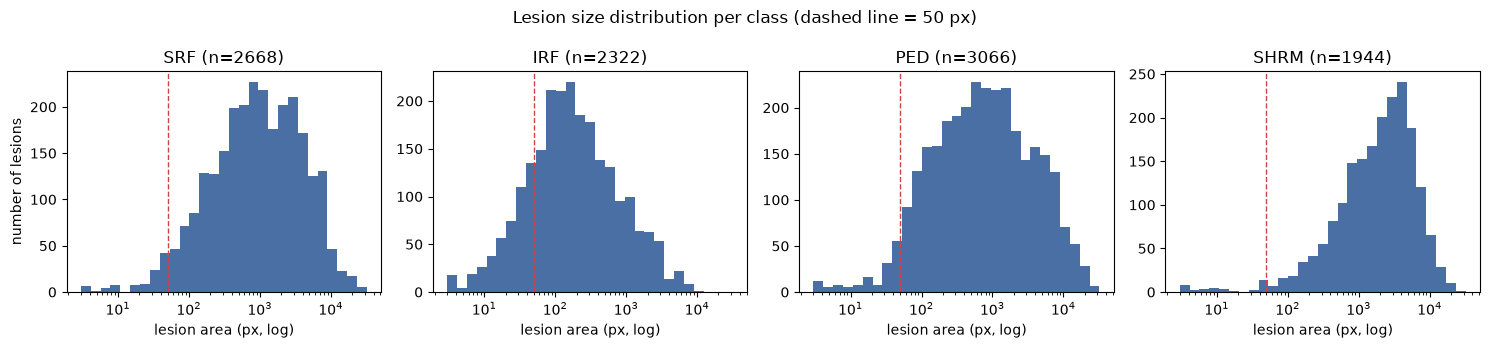

In [16]:
bins = np.logspace(np.log10(3), np.log10(per_lesion.area_px.max() + 1), 30)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, c in zip(axes, LESIONS):
    a = per_lesion.loc[per_lesion["class"] == c, "area_px"]
    ax.hist(a, bins=bins, color="#4a6fa5")
    ax.set_xscale("log"); ax.set_title(f"{c} (n={len(a)})"); ax.set_xlabel("lesion area (px, log)")
    ax.axvline(50, color="#c44", ls="--", lw=1)
axes[0].set_ylabel("number of lesions")
fig.suptitle("Lesion size distribution per class (dashed line = 50 px)")
fig.tight_layout(); fig.savefig("lesion_sizes.png", dpi=130)
plt.show()

## 5. Data-quality check: colour bleed at the seam

The OCT panel should be pure greyscale. Checking where colour appears shows it sits in the last
~10 columns, next to the mask: the mask colours bleed across the seam. **Crop those columns**
(or work in greyscale) so a model can't pick up label hints.

In [17]:
cols_with_colour = np.zeros(W, dtype=int)
for f in files[::10]:
    a = np.asarray(Image.open(f).convert("RGB"))[:, :W].astype(int)
    dev = np.abs(a - a.mean(-1, keepdims=True)).max(-1)
    cols_with_colour += (dev > 0).any(0)
print("columns where colour appears:", np.nonzero(cols_with_colour)[0])

CROP = 10
oct_clean = oct_img[:, : W - CROP]   # use this width downstream
print("clean scan shape:", oct_clean.shape)

columns where colour appears: [559 560 561 562 563 564 565 566 567 568 569]
clean scan shape: (380, 560)


## 6. Demographics

In [ ]:
try:
    demo = pd.read_excel(ROOT / "Demographics of the participants.xlsx")
    print("patients:", demo["Patient ID"].nunique(), " eyes:", demo["Eye ID"].nunique())
    print(demo["Sex"].value_counts().to_string())
    print("age range:", demo["Age(years)"].min(), "-", demo["Age(years)"].max(), " median", demo["Age(years)"].median())
    print("treatment-naive eyes:", (demo["time acquired"] == "naïve").sum())
    
    # patient-level leakage check (some patients contribute both eyes)
    eye_split = per_image.groupby("eye")["split"].first()
    demo["split"] = demo["Eye ID"].astype(str).map(eye_split)
    print("patients with eyes in both splits:", (demo.groupby("Patient ID")["split"].nunique() > 1).sum())
except ImportError as e:
    print("Skipping demographics: openpyxl is not installed (run: %pip install openpyxl). Nothing later depends on this cell.")

## 7. Scans for the denoising experiment

The 20 validation scans with the smallest IRF lesions: these are where a denoiser is most likely
to erase fluid.

Lesions under 20 px are skipped. At that size many are not real fluid but faint, blended mask pixels
left by resizing (a 2 px "lesion" is often a pale grey smudge in the mask, not green). 20 px is about
a 4 × 5 block, still very small.

In [20]:
MIN_LESION_PX = 20
irf_val = per_lesion[(per_lesion["class"] == "IRF") & (per_lesion["split"] == "val")
                     & (per_lesion["area_px"] >= MIN_LESION_PX)]
smallest = (irf_val.groupby("image")["area_px"].min().sort_values().head(20))
smallest.to_csv("smallest_irf_val.csv", header=["smallest_IRF_px"])
smallest

image
106_17.png    20
106_29.png    20
108_15.png    20
100_9.png     20
100_5.png     20
100_16.png    20
100_21.png    20
103_18.png    21
100_3.png     21
106_21.png    22
100_4.png     23
100_8.png     23
106_27.png    24
100_17.png    25
106_4.png     26
106_28.png    26
100_22.png    27
106_22.png    27
100_13.png    27
101_16.png    27
Name: area_px, dtype: int64

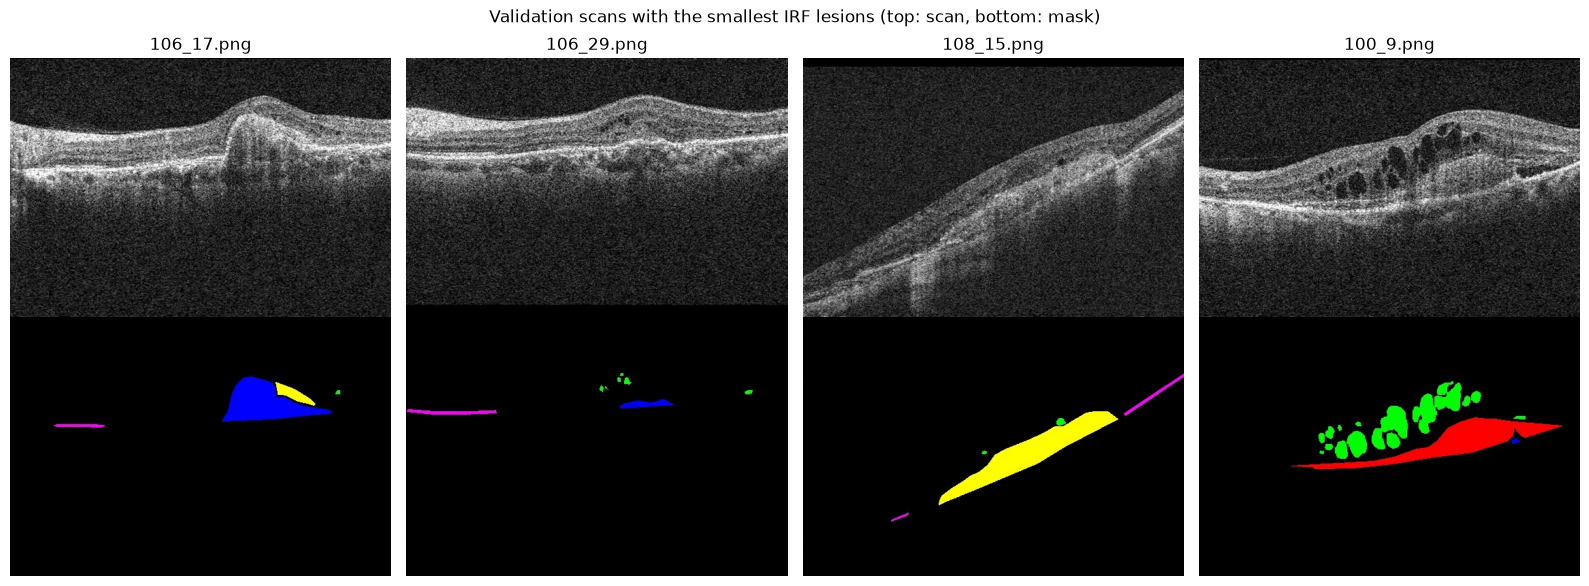

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax_pair, name in zip(axes.T, smallest.index[:4]):
    o, m = load(IMG_DIR / eye_of(name) / name)
    ax_pair[0].imshow(o[:, : W - CROP], cmap="gray"); ax_pair[0].set_title(name)
    ax_pair[1].imshow(m[:, : W - CROP])
    for a in ax_pair: a.axis("off")
fig.suptitle("Validation scans with the smallest IRF lesions (top: scan, bottom: mask)")
plt.tight_layout(); plt.show()

## 8. Does denoising erase small IRF lesions? (BM3D)

**BM3D** is a classical, training-free denoiser: it finds similar patches, stacks them, and filters
the stack so shared structure survives and random noise is removed. Its main setting is `sigma`,
the assumed noise strength; higher sigma means stronger smoothing.

OCT speckle is multiplicative, so the scan is log-transformed first (speckle becomes roughly
additive), denoised, then transformed back.

For each of the 20 scans picked in section 7, the code finds the **smallest IRF lesion** and
measures its **contrast**: how much darker the lesion is than a ring of tissue around it.
If denoising keeps the lesion, contrast stays about the same; if the lesion is being blurred into
its surroundings, contrast drops toward zero. No segmentation model is needed for this first test.

Install once: `uv pip install bm3d` (it includes an Apple Silicon build).

In [22]:
try:
    import bm3d
    def denoise(img01, sigma):
        return bm3d.bm3d(img01, sigma_psd=sigma)
    DENOISER = "BM3D"
except Exception as e:  # e.g. bm3d not installed
    from skimage.restoration import denoise_nl_means
    def denoise(img01, sigma):
        return denoise_nl_means(img01, h=0.8 * sigma, sigma=sigma, patch_size=7, patch_distance=11, fast_mode=True)
    DENOISER = "non-local means (fallback: bm3d unavailable)"
print("Denoiser:", DENOISER)

def denoise_oct(gray_u8, sigma):
    """Log-transform, denoise, transform back. Input/output: uint8 greyscale."""
    x = gray_u8.astype(np.float64)
    logx = np.log1p(x) / np.log(256.0)          # scale to roughly [0, 1]
    out = denoise(logx, sigma)
    back = np.expm1(np.clip(out, 0, 1) * np.log(256.0))
    return np.clip(back, 0, 255).astype(np.uint8)

IRF_ID = NAMES.index("IRF")

def smallest_irf(mask_rgb):
    """Binary mask of the smallest IRF lesion (>= MIN_LESION_PX) and its bounding box."""
    irf = decode(mask_rgb[:, : W - CROP]) == IRF_ID
    comp, n = ndimage.label(irf, structure=np.ones((3, 3)))
    areas = ndimage.sum(irf, comp, range(1, n + 1))
    ok = [i + 1 for i, a in enumerate(areas) if a >= MIN_LESION_PX]
    k = min(ok, key=lambda i: areas[i - 1])
    lesion = comp == k
    return lesion, ndimage.find_objects(lesion.astype(int))[0]

def contrast(img, lesion, ring_px=4):
    """Mean intensity of a ring around the lesion minus mean inside it (IRF is dark, so > 0)."""
    ring = ndimage.binary_dilation(lesion, iterations=ring_px) & ~lesion
    return img[ring].mean() - img[lesion].mean()

Denoiser: BM3D


In [23]:
import time
SIGMAS = [0.05, 0.10, 0.20]   # light, medium, strong smoothing (on the log scale)

results, examples = [], {}
t0 = time.time()
for i, name in enumerate(smallest.index):
    o, m = load(IMG_DIR / eye_of(name) / name)
    o = o[:, : W - CROP]
    lesion, box = smallest_irf(m)
    row = {"image": name, "lesion_px": int(lesion.sum()), "contrast_original": contrast(o, lesion)}
    den = {}
    for s in SIGMAS:
        d = denoise_oct(o, s)
        den[s] = d
        row[f"contrast_sigma{s}"] = contrast(d, lesion)
    results.append(row)
    examples[name] = (o, den, lesion, box, m[:, : W - CROP])
    print(f"{i + 1}/{len(smallest)} {name}  ({time.time() - t0:.0f}s)")

res = pd.DataFrame(results).set_index("image")
for s in SIGMAS:
    res[f"kept_sigma{s}"] = (res[f"contrast_sigma{s}"] / res["contrast_original"]).round(2)
res.to_csv("bm3d_small_irf_contrast.csv")
res.round(1)

1/20 106_17.png  (4s)
2/20 106_29.png  (9s)
3/20 108_15.png  (14s)
4/20 100_9.png  (19s)
5/20 100_5.png  (24s)
6/20 100_16.png  (28s)
7/20 100_21.png  (33s)
8/20 103_18.png  (37s)
9/20 100_3.png  (42s)
10/20 106_21.png  (47s)
11/20 100_4.png  (51s)
12/20 100_8.png  (56s)
13/20 106_27.png  (61s)
14/20 100_17.png  (66s)
15/20 106_4.png  (70s)
16/20 106_28.png  (75s)
17/20 100_22.png  (80s)
18/20 106_22.png  (86s)
19/20 100_13.png  (91s)
20/20 101_16.png  (95s)


,lesion_px,contrast_original,contrast_sigma0.05,contrast_sigma0.1,contrast_sigma0.2,kept_sigma0.05,kept_sigma0.1,kept_sigma0.2
image,,,,,,,,
106_17.png,20,71.1,67.6,59.7,25.6,1.0,0.8,0.4
106_29.png,20,23.5,23.4,24.2,16.1,1.0,1.0,0.7
108_15.png,20,18.4,18.4,19.1,12.7,1.0,1.0,0.7
100_9.png,20,37.3,36.2,29.7,12.2,1.0,0.8,0.3
100_5.png,20,64.1,60.0,43.4,17.7,0.9,0.7,0.3
100_16.png,20,60.6,58.9,53.7,37.0,1.0,0.9,0.6
100_21.png,20,44.2,40.3,28.8,13.5,0.9,0.6,0.3
103_18.png,21,30.9,29.5,25.3,13.8,1.0,0.8,0.4
100_3.png,21,48.6,48.3,39.9,14.6,1.0,0.8,0.3


`kept_sigma…` = fraction of the original lesion contrast that survives denoising
(1.0 = unchanged, below 1 = the lesion is fading into its surroundings, above 1 = it got more distinct).

Median fraction of lesion contrast kept (BM3D):
  sigma 0.05: 0.96
  sigma 0.1: 0.83
  sigma 0.2: 0.46


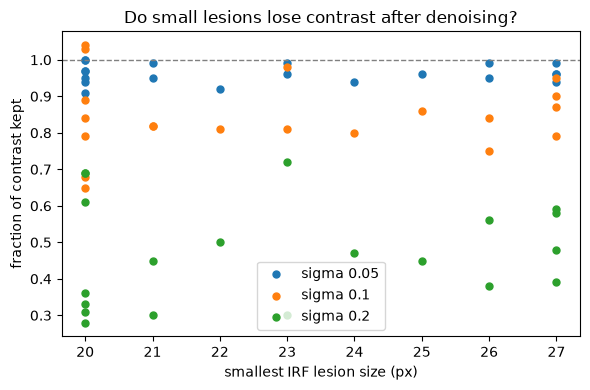

In [24]:
print(f"Median fraction of lesion contrast kept ({DENOISER}):")
for s in SIGMAS:
    print(f"  sigma {s}: {res[f'kept_sigma{s}'].median():.2f}")

fig, ax = plt.subplots(figsize=(6, 4))
for s in SIGMAS:
    ax.scatter(res["lesion_px"], res[f"kept_sigma{s}"], label=f"sigma {s}", s=25)
ax.axhline(1, color="grey", lw=1, ls="--")
ax.set_xlabel("smallest IRF lesion size (px)"); ax.set_ylabel("fraction of contrast kept")
ax.set_title("Do small lesions lose contrast after denoising?"); ax.legend()
plt.tight_layout(); plt.show()

### Look at them

Zoomed on the smallest IRF lesion in each scan. Top row: original. Middle rows: denoised at each sigma.
Bottom row: expert mask. The yellow outline marks the lesion. Ask: is the dark pocket still there?

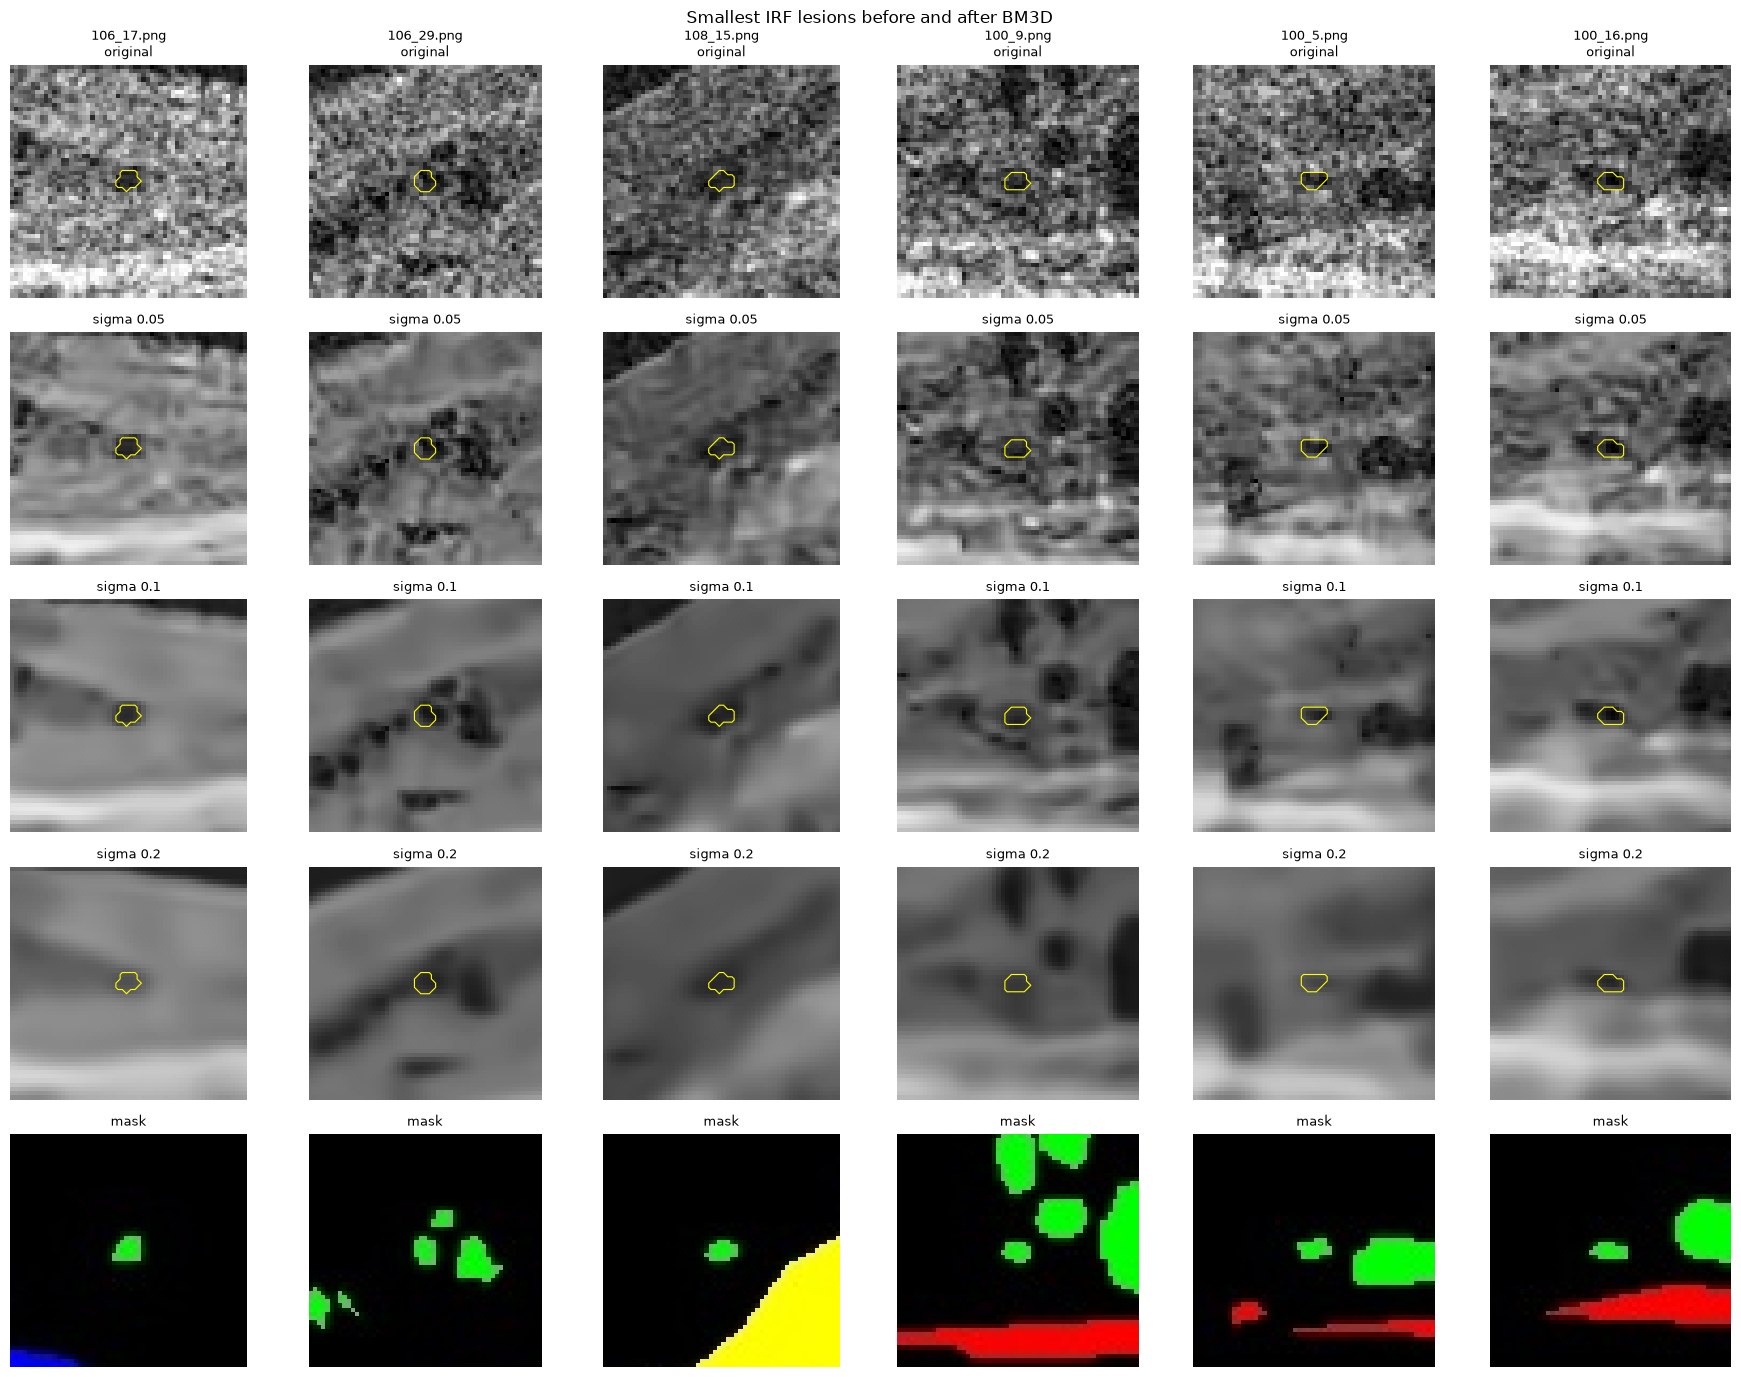

In [25]:
PAD = 25   # pixels of context around the lesion
show = list(examples)[:6]
rows = 2 + len(SIGMAS)
fig, axes = plt.subplots(rows, len(show), figsize=(3 * len(show), 2.8 * rows))
for j, name in enumerate(show):
    o, den, lesion, box, m = examples[name]
    y0 = max(box[0].start - PAD, 0); y1 = box[0].stop + PAD
    x0 = max(box[1].start - PAD, 0); x1 = box[1].stop + PAD
    crop = (slice(y0, y1), slice(x0, x1))
    panels = [("original", o)] + [(f"sigma {s}", den[s]) for s in SIGMAS]
    for r, (label, img) in enumerate(panels):
        ax = axes[r, j]
        ax.imshow(img[crop], cmap="gray", vmin=0, vmax=255)
        ax.contour(lesion[crop], levels=[0.5], colors="yellow", linewidths=0.8)
        ax.set_title(f"{name}\n{label}" if r == 0 else label, fontsize=9); ax.axis("off")
    axes[-1, j].imshow(m[crop]); axes[-1, j].set_title("mask", fontsize=9); axes[-1, j].axis("off")
fig.suptitle(f"Smallest IRF lesions before and after {DENOISER}")
plt.tight_layout(); plt.show()

## 9. Do small lesions fade more than large ones? (the H2 test)

Section 8 only looked at tiny IRF lesions. Smoothing lowers contrast everywhere, so on its own that
does not prove small lesions are *more* at risk. Here the same measurement is run on **lesions of
every size and every class** in a sample of validation scans, and compared.

If H2 is right, the fraction of contrast kept should **rise with lesion size**: tiny lesions fade,
large ones survive.

Two fixes compared with section 8:
- The ring of tissue around a lesion now **excludes other lesions**, so a big neighbouring fluid
  region does not distort the measurement.
- SHRM is *brighter* than its surroundings (other classes are darker). Contrast is measured with its
  sign, so "fraction kept" works the same way for both.

### 9a. What is a realistic sigma?

The sigmas in section 8 (0.05, 0.10, 0.20) were picked by hand. This cell estimates the actual noise
level of the scans on the same log scale BM3D sees, using a standard fast estimator
(Immerkær 1996: a high-pass filter that cancels smooth structure and leaves mostly noise).
A sigma near this estimate is what a careful user would choose; much higher is over-smoothing.

In [26]:
def to_log01(gray_u8):
    return np.log1p(gray_u8.astype(np.float64)) / np.log(256.0)   # same transform as denoise_oct

def estimate_noise(img):
    k = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], dtype=float)
    h, w = img.shape
    resp = np.abs(ndimage.convolve(img, k))[1:-1, 1:-1]
    return np.sqrt(np.pi / 2) * resp.sum() / (6 * (w - 2) * (h - 2))

rng = np.random.default_rng(0)
val_imgs = per_image.loc[per_image["split"] == "val", "image"].to_numpy()
noise = []
for name in rng.choice(val_imgs, size=40, replace=False):
    o, _ = load(IMG_DIR / eye_of(name) / name)
    noise.append(estimate_noise(to_log01(o[:, : W - CROP])))
SIGMA_EST = float(np.median(noise))
print(f"Estimated noise sigma (log scale): median {SIGMA_EST:.3f}, range {min(noise):.3f}-{max(noise):.3f}")

Estimated noise sigma (log scale): median 0.037, range 0.033-0.050


### 9b. Measure every lesion in a sample of validation scans

Each sampled scan is denoised once per sigma, and every lesion in it (>= 20 px, any class) is measured.
Half the scans are chosen from those containing IRF so small lesions are well represented.

`N_IMAGES = 60` takes roughly 5-8 minutes with BM3D. Lower it for a quick test, raise it for the
final numbers.

Besides contrast, each lesion now also gets a **contrast-to-noise ratio (CNR)**:

`CNR = |mean(ring) - mean(lesion)| / grain`

Contrast says how different the lesion is on average; **grain** is the pixel-to-pixel speckle
around it (the fine detail left after removing a slight 2-pixel blur, so retinal layers are not
mistaken for noise). Denoising lowers both, so CNR tells whether the lesion actually became **harder to tell
apart** (CNR falls) or just fainter on a cleaner background (CNR stays or rises).

Denoised images are saved to `denoised_cache/` so later steps (segmentation) can reuse them.

In [34]:
# 9b-1: settings, sample and measurement functions (quick; sections 9d and 10 need these)
N_IMAGES = 60
SIGMAS_ALL = sorted({0.05, round(SIGMA_EST, 3), 0.10, 0.20})
LESION_IDS = [NAMES.index(c) for c in LESIONS]
CACHE = Path("denoised_cache"); CACHE.mkdir(exist_ok=True)
print("sigmas:", SIGMAS_ALL)

val = per_image[per_image["split"] == "val"]
with_irf = val.loc[val["IRF_px"] > 0, "image"].to_numpy()
without_irf = val.loc[(val["IRF_px"] == 0) & (val[[f"{c}_px" for c in LESIONS]].sum(axis=1) > 0), "image"].to_numpy()
rng = np.random.default_rng(1)
sample = list(rng.choice(with_irf, N_IMAGES // 2, replace=False)) + \
         list(rng.choice(without_irf, N_IMAGES - N_IMAGES // 2, replace=False))

def ring_of(lesion, any_lesion, ring_px=4):
    return ndimage.binary_dilation(lesion, iterations=ring_px) & ~any_lesion

def signed_contrast(img, lesion, ring):
    return img[ring].mean() - img[lesion].mean()   # > 0 if lesion darker, < 0 if brighter

def cnr(img, lesion, ring):
    """|contrast| / local grain.
    Grain = spread of the fine detail left after removing a slight blur (Gaussian, 2 px),
    measured over the lesion and its ring. Slow anatomical changes (layers) are removed by the
    blur, so they are not counted as noise; pixel-to-pixel speckle is."""
    x = img.astype(float)
    fine = x - ndimage.gaussian_filter(x, 2)
    noise = fine[ring | lesion].std()
    return abs(x[ring].mean() - x[lesion].mean()) / noise if noise > 0 else np.nan

def denoised(name, o, s):
    """Denoise once, then reuse the saved PNG on later runs."""
    f = CACHE / f"{Path(name).stem}_s{s}.png"
    if f.exists():
        return np.asarray(Image.open(f))
    d = denoise_oct(o, s)
    Image.fromarray(d).save(f)
    return d

sigmas: [0.037, 0.05, 0.1, 0.2]


In [35]:
# 9b-2: measure the 60 sampled scans (about 15 min the first time, fast afterwards thanks to the cache)
rows, t0 = [], time.time()
for i, name in enumerate(sample):
    o, m = load(IMG_DIR / eye_of(name) / name)
    o, m = o[:, : W - CROP], m[:, : W - CROP]
    lab = decode(m)
    any_lesion = np.isin(lab, LESION_IDS)
    den = {s: denoised(name, o, s) for s in SIGMAS_ALL}
    for cname in LESIONS:
        binary = lab == NAMES.index(cname)
        comp, n = ndimage.label(binary, structure=np.ones((3, 3)))
        for k in range(1, n + 1):
            lesion = comp == k
            area = int(lesion.sum())
            if area < MIN_LESION_PX:
                continue
            ring = ring_of(lesion, any_lesion)
            if ring.sum() < 10:
                continue
            c0 = signed_contrast(o, lesion, ring)
            if abs(c0) < 10:   # lesion barely visible to begin with: skip
                continue
            row = {"image": name, "eye": eye_of(name), "class": cname, "area_px": area,
                   "contrast_original": c0, "cnr_original": cnr(o, lesion, ring)}
            for s in SIGMAS_ALL:
                row[f"kept_{s}"] = signed_contrast(den[s], lesion, ring) / c0
                row[f"cnr_{s}"] = cnr(den[s], lesion, ring)
                row[f"cnr_ratio_{s}"] = row[f"cnr_{s}"] / row["cnr_original"]
            rows.append(row)
    print(f"{i + 1}/{len(sample)} {name}  lesions so far: {len(rows)}  ({time.time() - t0:.0f}s)")

allres = pd.DataFrame(rows)
allres.to_csv("contrast_kept_by_size.csv", index=False)
print(len(allres), "lesions from", allres["image"].nunique(), "scans")
allres.groupby("class").size()

1/60 106_9.png  lesions so far: 1  (6s)
2/60 106_28.png  lesions so far: 5  (12s)
3/60 105_20.png  lesions so far: 9  (18s)
4/60 100_2.png  lesions so far: 19  (24s)
5/60 100_4.png  lesions so far: 38  (30s)
6/60 122_22.png  lesions so far: 41  (36s)
7/60 106_19.png  lesions so far: 45  (42s)
8/60 108_15.png  lesions so far: 48  (49s)
9/60 111_20.png  lesions so far: 53  (55s)
10/60 100_12.png  lesions so far: 62  (61s)
11/60 115_15.png  lesions so far: 65  (68s)
12/60 103_16.png  lesions so far: 73  (74s)
13/60 103_21.png  lesions so far: 80  (80s)
14/60 106_27.png  lesions so far: 83  (86s)
15/60 124_20.png  lesions so far: 87  (93s)
16/60 118_3.png  lesions so far: 89  (99s)
17/60 115_16.png  lesions so far: 92  (105s)
18/60 106_12.png  lesions so far: 95  (112s)
19/60 103_18.png  lesions so far: 101  (118s)
20/60 105_28.png  lesions so far: 103  (124s)
21/60 100_3.png  lesions so far: 117  (130s)
22/60 105_27.png  lesions so far: 121  (137s)
23/60 100_13.png  lesions so far: 131  (

class
IRF     99
PED     33
SHRM    26
SRF     69
dtype: int64

### 9c. Fraction of contrast kept, by lesion size

Lesions are grouped into size bins. Each cell is the **median fraction of contrast kept**.
If H2 holds, numbers should increase from left (small) to right (large), especially at strong sigma.

In [36]:
BINS = [20, 50, 200, 1000, 5000, np.inf]
BIN_LABELS = ["20-50", "50-200", "200-1k", "1k-5k", ">5k"]
allres["size_bin"] = pd.cut(allres["area_px"], BINS, labels=BIN_LABELS, right=False)

by_size = allres.groupby("size_bin", observed=False)[[f"kept_{s}" for s in SIGMAS_ALL]].median().round(2)
by_size["n_lesions"] = allres.groupby("size_bin", observed=False).size()
by_size

,kept_0.037,kept_0.05,kept_0.1,kept_0.2,n_lesions
size_bin,,,,,
20-50,0.98,0.97,0.91,0.54,27
50-200,0.97,0.95,0.90,0.69,57
200-1k,0.98,0.97,0.92,0.81,71
1k-5k,0.99,0.98,0.94,0.87,40
>5k,0.99,0.99,0.96,0.90,32


In [37]:
from scipy.stats import spearmanr
print("Does fraction kept rise with lesion size?  (Spearman rho > 0 = yes; p < 0.05 = unlikely by chance)\n")
for s in SIGMAS_ALL:
    rho, p = spearmanr(allres["area_px"], allres[f"kept_{s}"], nan_policy="omit")
    irf = allres[allres["class"] == "IRF"]
    rho_i, p_i = spearmanr(irf["area_px"], irf[f"kept_{s}"], nan_policy="omit")
    print(f"sigma {s:<6}  all lesions: rho={rho:+.2f} (p={p:.1e})    IRF only: rho={rho_i:+.2f} (p={p_i:.1e})")

Does fraction kept rise with lesion size?  (Spearman rho > 0 = yes; p < 0.05 = unlikely by chance)

sigma 0.037   all lesions: rho=+0.31 (p=1.6e-06)    IRF only: rho=+0.00 (p=9.9e-01)
sigma 0.05    all lesions: rho=+0.36 (p=2.3e-08)    IRF only: rho=+0.01 (p=8.8e-01)
sigma 0.1     all lesions: rho=+0.36 (p=2.7e-08)    IRF only: rho=+0.26 (p=1.1e-02)
sigma 0.2     all lesions: rho=+0.57 (p=1.0e-20)    IRF only: rho=+0.67 (p=4.1e-14)


The **IRF-only** line matters: it compares small and large lesions *of the same type*, so the effect
cannot be explained by IRF simply being a different kind of lesion from SRF or PED.

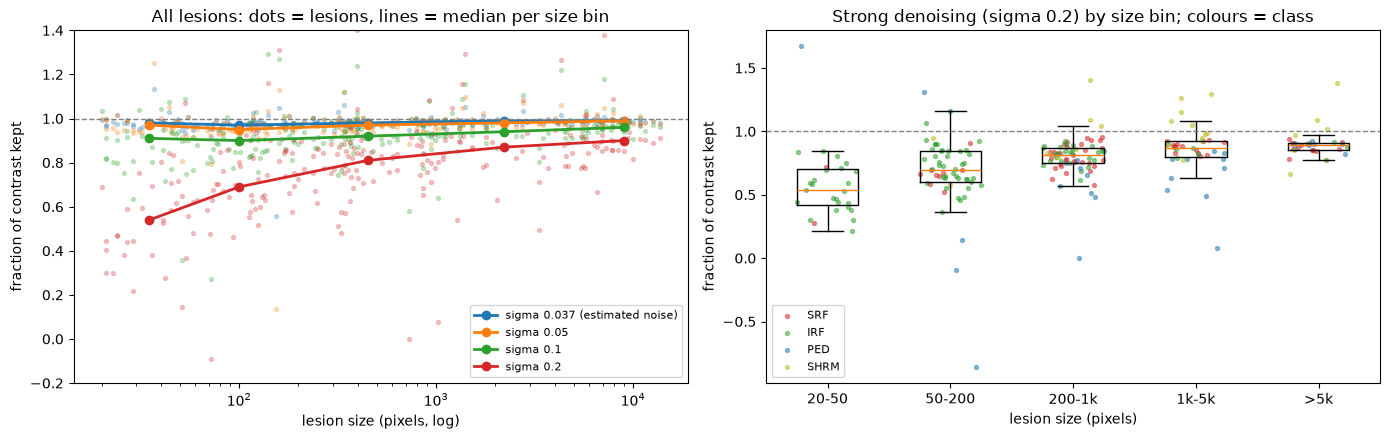

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# left: every lesion, fraction kept vs size, one colour per sigma, with binned medians
ax = axes[0]
centres = [35, 100, 450, 2200, 9000]
for s in SIGMAS_ALL:
    ax.scatter(allres["area_px"], allres[f"kept_{s}"], s=8, alpha=0.25)
    ax.plot(centres[: len(by_size)], by_size[f"kept_{s}"], marker="o", lw=2,
            label=f"sigma {s}" + (" (estimated noise)" if s == round(SIGMA_EST, 3) else ""))
ax.set_xscale("log"); ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_ylim(-0.2, 1.4)
ax.set_xlabel("lesion size (pixels, log)"); ax.set_ylabel("fraction of contrast kept")
ax.set_title("All lesions: dots = lesions, lines = median per size bin"); ax.legend(fontsize=8)

# right: strongest sigma, box per size bin, split by class
ax = axes[1]
s_hi = max(SIGMAS_ALL)
data = [allres.loc[allres["size_bin"] == b, f"kept_{s_hi}"].dropna() for b in BIN_LABELS]
try:
    ax.boxplot(data, tick_labels=BIN_LABELS, showfliers=False)   # matplotlib >= 3.9
except TypeError:
    ax.boxplot(data, labels=BIN_LABELS, showfliers=False)        # older matplotlib
for j, b in enumerate(BIN_LABELS, start=1):
    sub = allres[allres["size_bin"] == b]
    for cname, col in zip(LESIONS, ["#d62728", "#2ca02c", "#1f77b4", "#bcbd22"]):
        v = sub.loc[sub["class"] == cname, f"kept_{s_hi}"]
        ax.scatter(np.full(len(v), j) + rng.uniform(-0.25, 0.25, len(v)), v, s=8, color=col, alpha=0.5,
                   label=cname if j == 1 else None)
ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_xlabel("lesion size (pixels)"); ax.set_ylabel("fraction of contrast kept")
ax.set_title(f"Strong denoising (sigma {s_hi}) by size bin; colours = class"); ax.legend(fontsize=8)

plt.tight_layout(); plt.savefig("contrast_kept_by_size.png", dpi=130); plt.show()

### How to read this

- **Left plot:** if the lines slope upward from left to right, larger lesions keep more of their
  contrast, so small ones are more at risk. The steeper the slope at a given sigma, the stronger the
  size effect at that denoising strength.
- **Right plot:** at the strongest setting, compare the box for 20-50 px with the box for >5k px.
  A large gap is the H2 result. The coloured dots show whether this holds within each class.
- **Estimated-noise sigma:** the realistic setting. If small lesions already fade at this sigma, the
  problem affects ordinary use, not only aggressive over-smoothing.
- Caveat: contrast is a proxy. The final test is whether a segmentation model still detects the
  lesion; that comes next.

### 9d. Contrast-to-noise: does the lesion get harder to see, or just fainter?

`cnr_ratio` = CNR after denoising / CNR before.
- **above 1**: the lesion stands out *more* than in the grainy original (denoising helped)
- **about 1**: no change in how distinguishable it is
- **below 1**: the lesion is genuinely harder to tell apart from its surroundings

The real question for H2: does strong denoising push **small** lesions below 1 while large ones
stay above it?

In [39]:
if "cnr_ratio_0.2" not in allres.columns:
    raise RuntimeError("allres has no CNR columns: run the two 9b cells above first (9b-1 and 9b-2), then rerun from 9c.")
allres["size_bin"] = pd.cut(allres["area_px"], BINS, labels=BIN_LABELS, right=False)
cnr_by_size = allres.groupby("size_bin", observed=False)[[f"cnr_ratio_{s}" for s in SIGMAS_ALL]].median().round(2)
cnr_by_size["n_lesions"] = allres.groupby("size_bin", observed=False).size()
print("Median CNR ratio (after / before) by lesion size")
cnr_by_size

Median CNR ratio (after / before) by lesion size


,cnr_ratio_0.037,cnr_ratio_0.05,cnr_ratio_0.1,cnr_ratio_0.2,n_lesions
size_bin,,,,,
20-50,1.16,1.34,2.03,2.88,27
50-200,1.16,1.35,2.30,3.46,57
200-1k,1.19,1.35,1.99,2.83,71
1k-5k,1.29,1.55,2.90,3.62,40
>5k,1.33,1.67,2.76,3.77,32


In [40]:
print("Share of lesions that became HARDER to distinguish (CNR ratio < 1), by size:")
share = allres.groupby("size_bin", observed=False)[[f"cnr_ratio_{s}" for s in SIGMAS_ALL]] \
              .agg(lambda v: (v < 1).mean()).round(2)
share

Share of lesions that became HARDER to distinguish (CNR ratio < 1), by size:


,cnr_ratio_0.037,cnr_ratio_0.05,cnr_ratio_0.1,cnr_ratio_0.2
size_bin,,,,
20-50,0.00,0.00,0.0,0.00
50-200,0.02,0.02,0.0,0.02
200-1k,0.00,0.00,0.0,0.01
1k-5k,0.00,0.00,0.0,0.02
>5k,0.00,0.00,0.0,0.00


In [41]:
print("Does CNR ratio rise with lesion size?  (Spearman)\n")
for s in SIGMAS_ALL:
    rho, p = spearmanr(allres["area_px"], allres[f"cnr_ratio_{s}"], nan_policy="omit")
    irf = allres[allres["class"] == "IRF"]
    rho_i, p_i = spearmanr(irf["area_px"], irf[f"cnr_ratio_{s}"], nan_policy="omit")
    print(f"sigma {s:<6}  all lesions: rho={rho:+.2f} (p={p:.1e})    IRF only: rho={rho_i:+.2f} (p={p_i:.1e})")

Does CNR ratio rise with lesion size?  (Spearman)

sigma 0.037   all lesions: rho=+0.33 (p=3.9e-07)    IRF only: rho=-0.36 (p=3.0e-04)
sigma 0.05    all lesions: rho=+0.31 (p=2.0e-06)    IRF only: rho=-0.38 (p=8.9e-05)
sigma 0.1     all lesions: rho=+0.29 (p=1.2e-05)    IRF only: rho=-0.11 (p=3.0e-01)
sigma 0.2     all lesions: rho=+0.23 (p=4.2e-04)    IRF only: rho=+0.10 (p=3.5e-01)


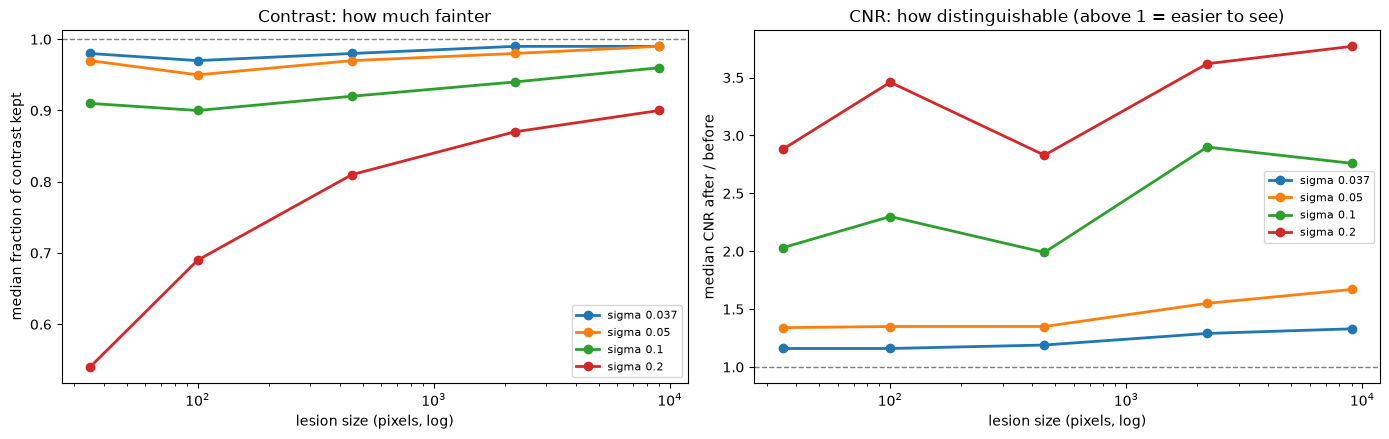

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
centres = [35, 100, 450, 2200, 9000]

ax = axes[0]
for s in SIGMAS_ALL:
    ax.plot(centres[: len(by_size)], by_size[f"kept_{s}"], marker="o", lw=2, label=f"sigma {s}")
ax.set_xscale("log"); ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_xlabel("lesion size (pixels, log)"); ax.set_ylabel("median fraction of contrast kept")
ax.set_title("Contrast: how much fainter"); ax.legend(fontsize=8)

ax = axes[1]
for s in SIGMAS_ALL:
    ax.plot(centres[: len(cnr_by_size)], cnr_by_size[f"cnr_ratio_{s}"], marker="o", lw=2, label=f"sigma {s}")
ax.set_xscale("log"); ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_xlabel("lesion size (pixels, log)"); ax.set_ylabel("median CNR after / before")
ax.set_title("CNR: how distinguishable (above 1 = easier to see)"); ax.legend(fontsize=8)

plt.tight_layout(); plt.savefig("cnr_by_size.png", dpi=130); plt.show()

### How to read 9d

- If the **right plot** stays above 1 for every size, denoising makes all lesions easier to see even
  though they get fainter: the contrast loss in 9c was compensated by noise removal.
- If small lesions drop **below 1** at strong sigma while large ones stay above, H2 holds on the
  stronger measure: over-smoothing makes small lesions genuinely harder to detect.
- Caveat: grain is measured over a small area for small lesions, so their CNR is a noisier estimate.
  The definitive test remains whether a segmentation model still detects the lesion.

## 10. Full validation run (all 703 scans), with checkpoints

Same measurement as section 9 (contrast kept + CNR), on **every validation scan with a lesion**,
for the final numbers.

**Checkpoints:** results are appended to `full_val_results.csv` after every scan, and finished scans
are listed in `full_val_done.txt`. If the run stops (Mac sleeps, kernel restarts, you interrupt it),
just run the cells again from the top: finished scans are skipped and denoised images are reused
from `denoised_cache/`, so it continues where it stopped.

**Time:** about 15 s per scan with BM3D, so roughly 3 hours the first time (the 60 scans from
section 9 are already cached). Keep the Mac plugged in with the lid open; the cell below also stops
macOS from sleeping while it runs.

**Needs:** sections 1-9a and the cell **9b-1** run first in this session (they define the functions used here).
The 60-scan run (9b-2) and 9c-9d are optional before this; they are not needed for section 10.

In [43]:
for _f in ["denoised", "ring_of", "cnr", "signed_contrast", "SIGMAS_ALL", "LESION_IDS", "BINS"]:
    assert _f in globals(), f"{_f} is not defined: run sections 1-9a and cell 9b-1 first"
import os, sys, subprocess

FULL_CSV = Path("full_val_results.csv")
DONE_TXT = Path("full_val_done.txt")
MAX_SCANS = None   # set to e.g. 10 for a quick test; None = all

# keep the Mac awake while this kernel is alive (macOS only)
if sys.platform == "darwin":
    subprocess.Popen(["caffeinate", "-i", "-w", str(os.getpid())])

def measure_scan(name):
    o, m = load(IMG_DIR / eye_of(name) / name)
    o, m = o[:, : W - CROP], m[:, : W - CROP]
    lab = decode(m)
    any_lesion = np.isin(lab, LESION_IDS)
    den = {s: denoised(name, o, s) for s in SIGMAS_ALL}
    out = []
    for cname in LESIONS:
        comp, n = ndimage.label(lab == NAMES.index(cname), structure=np.ones((3, 3)))
        for k in range(1, n + 1):
            lesion = comp == k
            area = int(lesion.sum())
            if area < MIN_LESION_PX:
                continue
            ring = ring_of(lesion, any_lesion)
            if ring.sum() < 10:
                continue
            c0 = signed_contrast(o, lesion, ring)
            if abs(c0) < 10:
                continue
            row = {"image": name, "eye": eye_of(name), "class": cname, "area_px": area,
                   "contrast_original": c0, "cnr_original": cnr(o, lesion, ring)}
            for s in SIGMAS_ALL:
                row[f"kept_{s}"] = signed_contrast(den[s], lesion, ring) / c0
                row[f"cnr_{s}"] = cnr(den[s], lesion, ring)
                row[f"cnr_ratio_{s}"] = row[f"cnr_{s}"] / row["cnr_original"]
            out.append(row)
    return out

val = per_image[per_image["split"] == "val"]
todo_all = val.loc[val[[f"{c}_px" for c in LESIONS]].sum(axis=1) > 0, "image"].tolist()
if MAX_SCANS:
    todo_all = todo_all[:MAX_SCANS]
done = set(DONE_TXT.read_text().split()) if DONE_TXT.exists() else set()
todo = [n for n in todo_all if n not in done]
print(f"{len(todo_all)} validation scans with lesions; {len(done & set(todo_all))} already done; {len(todo)} to go")
print("sigmas:", SIGMAS_ALL)

t0 = time.time()
for i, name in enumerate(todo):
    rows = measure_scan(name)
    if rows:
        pd.DataFrame(rows).to_csv(FULL_CSV, mode="a", header=not FULL_CSV.exists(), index=False)
    with open(DONE_TXT, "a") as fh:
        fh.write(name + "\n")
    if (i + 1) % 10 == 0 or i + 1 == len(todo):
        rate = (time.time() - t0) / (i + 1)
        print(f"{i + 1}/{len(todo)}  {rate:.1f}s/scan  about {rate * (len(todo) - i - 1) / 60:.0f} min left")
print("finished")

626 validation scans with lesions; 0 already done; 626 to go
sigmas: [0.037, 0.05, 0.1, 0.2]
10/626  6.5s/scan  about 67 min left
20/626  5.9s/scan  about 59 min left
30/626  5.5s/scan  about 55 min left
40/626  5.9s/scan  about 57 min left
50/626  6.1s/scan  about 58 min left
60/626  6.2s/scan  about 58 min left
70/626  6.3s/scan  about 59 min left
80/626  6.3s/scan  about 57 min left
90/626  6.2s/scan  about 56 min left
100/626  6.4s/scan  about 56 min left
110/626  6.5s/scan  about 56 min left
120/626  6.5s/scan  about 55 min left
130/626  6.6s/scan  about 55 min left
140/626  6.6s/scan  about 53 min left
150/626  6.5s/scan  about 52 min left
160/626  6.5s/scan  about 51 min left
170/626  6.5s/scan  about 49 min left
180/626  6.5s/scan  about 48 min left
190/626  6.4s/scan  about 47 min left
200/626  6.4s/scan  about 46 min left
210/626  6.5s/scan  about 45 min left
220/626  6.4s/scan  about 43 min left
230/626  6.4s/scan  about 42 min left
240/626  6.4s/scan  about 41 min left
250/

### 10b. Results on the full validation set

Same tables and test as sections 9c-9d, plus a **confidence interval** for the key comparison:
how much more contrast/CNR large lesions keep than small ones. The interval comes from resampling
whole **eyes** (not single lesions), because lesions from the same eye are not independent.
If the interval does not include 0, the size effect is unlikely to be chance.

In [44]:
if not FULL_CSV.exists():
    raise RuntimeError("No results yet: run the section 10 cell above first (with MAX_SCANS small, the first scans may contain no measurable lesion; increase it).")
full = pd.read_csv(FULL_CSV).drop_duplicates(subset=["image", "class", "area_px", "contrast_original"])
full["eye"] = full["eye"].astype(str)
full["size_bin"] = pd.cut(full["area_px"], BINS, labels=BIN_LABELS, right=False)
print(len(full), "lesions from", full["image"].nunique(), "scans,", full["eye"].nunique(), "eyes")
print(full.groupby("class").size().to_string())

def bin_table(df, prefix):
    t = df.groupby("size_bin", observed=False)[[f"{prefix}{s}" for s in SIGMAS_ALL]].median().round(2)
    t["n_lesions"] = df.groupby("size_bin", observed=False).size()
    return t

print("\nMedian fraction of CONTRAST kept, by size")
display(bin_table(full, "kept_"))
print("Median CNR after / before, by size  (above 1 = easier to see)")
display(bin_table(full, "cnr_ratio_"))
print("Share of lesions HARDER to see (CNR ratio < 1), by size")
display(full.groupby("size_bin", observed=False)[[f"cnr_ratio_{s}" for s in SIGMAS_ALL]]
            .agg(lambda v: (v < 1).mean()).round(2))

1723 lesions from 604 scans, 31 eyes
class
IRF     480
PED     380
SHRM    305
SRF     558

Median fraction of CONTRAST kept, by size


,kept_0.037,kept_0.05,kept_0.1,kept_0.2,n_lesions
size_bin,,,,,
20-50,0.98,0.96,0.86,0.53,103
50-200,0.98,0.96,0.90,0.70,339
200-1k,0.98,0.98,0.94,0.83,539
1k-5k,0.99,0.98,0.96,0.89,473
>5k,0.99,0.99,0.97,0.90,269


Median CNR after / before, by size  (above 1 = easier to see)


,cnr_ratio_0.037,cnr_ratio_0.05,cnr_ratio_0.1,cnr_ratio_0.2,n_lesions
size_bin,,,,,
20-50,1.16,1.34,1.95,2.48,103
50-200,1.19,1.39,2.07,2.78,339
200-1k,1.25,1.46,2.22,2.87,539
1k-5k,1.29,1.55,2.57,3.60,473
>5k,1.32,1.65,2.80,3.74,269


Share of lesions HARDER to see (CNR ratio < 1), by size


,cnr_ratio_0.037,cnr_ratio_0.05,cnr_ratio_0.1,cnr_ratio_0.2
size_bin,,,,
20-50,0.0,0.0,0.01,0.05
50-200,0.0,0.0,0.02,0.04
200-1k,0.0,0.0,0.01,0.03
1k-5k,0.0,0.0,0.00,0.00
>5k,0.0,0.0,0.00,0.00


In [45]:
print("Spearman: does the measure rise with lesion size?\n")
for prefix, label in [("kept_", "contrast kept"), ("cnr_ratio_", "CNR ratio")]:
    print(label)
    for s in SIGMAS_ALL:
        rho, p = spearmanr(full["area_px"], full[f"{prefix}{s}"], nan_policy="omit")
        irf = full[full["class"] == "IRF"]
        rho_i, p_i = spearmanr(irf["area_px"], irf[f"{prefix}{s}"], nan_policy="omit")
        print(f"  sigma {s:<6} all: rho={rho:+.2f} (p={p:.1e})   IRF only: rho={rho_i:+.2f} (p={p_i:.1e})")
    print()

Spearman: does the measure rise with lesion size?

contrast kept
  sigma 0.037  all: rho=+0.23 (p=5.6e-23)   IRF only: rho=-0.03 (p=5.1e-01)
  sigma 0.05   all: rho=+0.31 (p=2.1e-39)   IRF only: rho=+0.01 (p=7.5e-01)
  sigma 0.1    all: rho=+0.38 (p=1.1e-58)   IRF only: rho=+0.35 (p=4.6e-15)
  sigma 0.2    all: rho=+0.53 (p=1.6e-127)   IRF only: rho=+0.69 (p=4.7e-68)

CNR ratio
  sigma 0.037  all: rho=+0.28 (p=2.7e-31)   IRF only: rho=-0.30 (p=2.8e-11)
  sigma 0.05   all: rho=+0.31 (p=7.2e-41)   IRF only: rho=-0.22 (p=7.7e-07)
  sigma 0.1    all: rho=+0.40 (p=1.5e-66)   IRF only: rho=+0.23 (p=4.2e-07)
  sigma 0.2    all: rho=+0.34 (p=1.3e-48)   IRF only: rho=+0.40 (p=2.5e-20)



In [46]:
# Small (< 200 px) vs large (>= 1000 px): difference in median, 95% CI by resampling eyes
small = full["area_px"] < 200
large = full["area_px"] >= 1000
eyes = full["eye"].unique()
by_eye = {e: g for e, g in full.groupby("eye")}
rng_b = np.random.default_rng(42)

def gap(df, col):
    s, l = df.loc[df["area_px"] < 200, col], df.loc[df["area_px"] >= 1000, col]
    return l.median() - s.median() if len(s) and len(l) else np.nan

rows = []
for prefix, label in [("kept_", "contrast kept"), ("cnr_ratio_", "CNR ratio")]:
    for s in SIGMAS_ALL:
        col = f"{prefix}{s}"
        boots = []
        for _ in range(1000):
            pick = rng_b.choice(eyes, len(eyes), replace=True)
            boots.append(gap(pd.concat([by_eye[e] for e in pick]), col))
        lo, hi = np.nanpercentile(boots, [2.5, 97.5])
        rows.append({"measure": label, "sigma": s, "large minus small": round(gap(full, col), 3),
                     "95% CI": f"[{lo:.3f}, {hi:.3f}]", "CI excludes 0": lo > 0 or hi < 0})
gap_table = pd.DataFrame(rows)
gap_table.to_csv("full_val_size_gap.csv", index=False)
print(f"small = under 200 px (n={small.sum()}), large = 1000 px or more (n={large.sum()})")
gap_table

small = under 200 px (n=442), large = 1000 px or more (n=742)


,measure,sigma,large minus small,95% CI,CI excludes 0
0,contrast kept,0.037,0.009,"[0.006, 0.013]",True
1,contrast kept,0.050,0.022,"[0.016, 0.030]",True
2,contrast kept,0.100,0.070,"[0.054, 0.094]",True
3,contrast kept,0.200,0.239,"[0.194, 0.291]",True
4,CNR ratio,0.037,0.119,"[0.040, 0.215]",True
5,CNR ratio,0.050,0.214,"[0.080, 0.459]",True
6,CNR ratio,0.100,0.647,"[0.301, 1.392]",True
7,CNR ratio,0.200,1.033,"[0.512, 2.581]",True


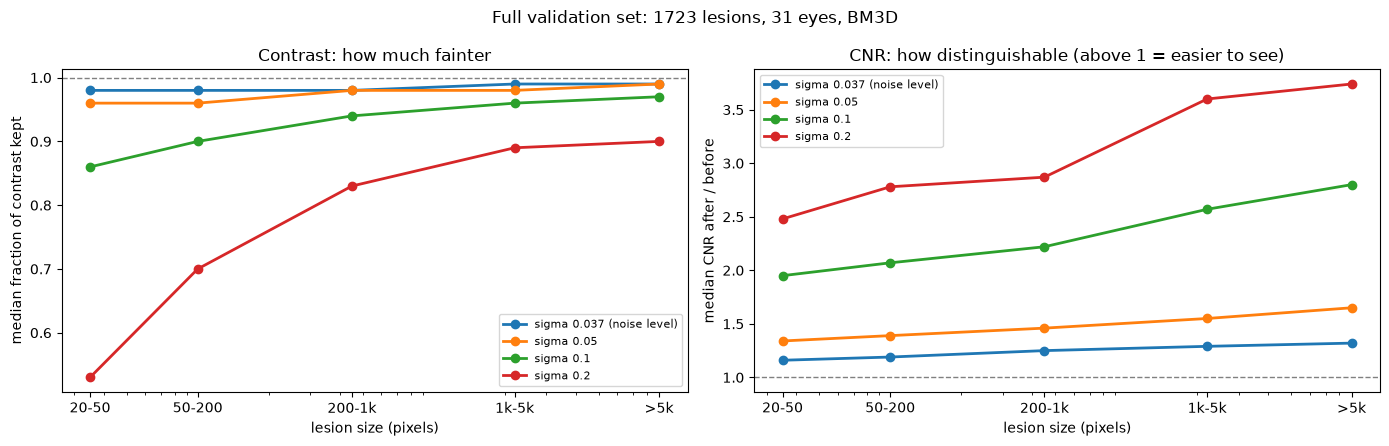

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
centres = [35, 100, 450, 2200, 9000]
for ax, prefix, title, ylab in [
        (axes[0], "kept_", "Contrast: how much fainter", "median fraction of contrast kept"),
        (axes[1], "cnr_ratio_", "CNR: how distinguishable (above 1 = easier to see)", "median CNR after / before")]:
    t = bin_table(full, prefix)
    for s in SIGMAS_ALL:
        ax.plot(centres, t[f"{prefix}{s}"], marker="o", lw=2,
                label=f"sigma {s}" + (" (noise level)" if s == round(SIGMA_EST, 3) else ""))
    ax.set_xscale("log"); ax.axhline(1, color="grey", ls="--", lw=1)
    ax.set_xticks(centres); ax.set_xticklabels(BIN_LABELS)
    ax.set_xlabel("lesion size (pixels)"); ax.set_ylabel(ylab); ax.set_title(title); ax.legend(fontsize=8)
fig.suptitle(f"Full validation set: {len(full)} lesions, {full['eye'].nunique()} eyes, BM3D")
plt.tight_layout(); plt.savefig("full_val_by_size.png", dpi=150); plt.show()

### What to write down from section 10

- The two size tables (contrast and CNR) at the noise-level sigma and at sigma 0.2.
- The `gap_table`: if "CI excludes 0" is True at strong sigma and False at the noise-level sigma,
  that is the H2 result in one line: *the size effect appears only with over-smoothing*.
- `full_val_by_size.png` is a candidate figure for the ISBI abstract.